# Práctica N.° 02 — Símplex, dualidad y análisis de sensibilidad
**Curso:** Optimización de Procesos

**Integrantes:**
1. Honorio Menendez Sacaca  
2. Alexander Vilcapaza Chavez
3. Jhony Fermin Quenta Chura


### **Actividad 0. Preparación del entorno**

In [ ]:
%pip install -q pulp==3.3.2 highspy numpy scipy matplotlib
import pulp, highspy, numpy as np, matplotlib.pyplot as plt
print('PuLP:', pulp.__version__)
print('Solvers:', pulp.listSolvers(onlyAvailable=True))

PuLP: 3.3.2
Solvers: ['PULP_CBC_CMD', 'HiGHS']


### **Actividad 1. Método símplex paso a paso**
Modelo:  
$\max Z=9x_1+2.5x_2$  
s.a. $8x_1+x_2\le2400$, $6x_1+3x_2\le2700$, $x_2\le600$, $x_1,x_2\ge0$.

In [ ]:
from fractions import Fraction as F

def mostrar(T, base, nombres):
    print('Base ' + ''.join(f'{n:>8}' for n in nombres + ['LD']))
    for b, fila in zip(base + ['Z'], T):
        print(f'{b:5} ' + ''.join(f'{str(v):>8}' for v in fila))
    print()

def simplex(T, base, nombres, verbose=True, regla='mas_negativa'):
    m = len(T) - 1
    it = 0
    historial = []
    while True:
        valores = {n:F(0) for n in nombres}
        for b, fila in zip(base, T[:-1]):
            valores[b] = fila[-1]
        historial.append((it, valores.copy()))
        if verbose:
            print(f'Iteración {it}'); mostrar(T, base, nombres)
        z = T[-1]
        negativos = [j for j in range(len(nombres)) if z[j] < 0]
        if not negativos:
            return T, base, historial
        if regla == 'ultima_negativa':
            e = max(negativos)
        else:
            e = min(negativos, key=lambda j: z[j])
        # TODO completado: prueba de razón mínima
        razones = [(T[i][-1] / T[i][e], i) for i in range(m) if T[i][e] > 0]
        if not razones:
            raise ValueError('Problema no acotado')
        r = min(razones)[1]
        piv = T[r][e]
        T[r] = [v / piv for v in T[r]]
        for i in range(m + 1):
            if i != r:
                f = T[i][e]
                T[i] = [a - f*b for a,b in zip(T[i],T[r])]
        base[r] = nombres[e]
        it += 1

nombres = ['x1','x2','s1','s2','s3']
T0 = [[F(8),F(1),F(1),F(0),F(0),F(2400)],
      [F(6),F(3),F(0),F(1),F(0),F(2700)],
      [F(0),F(1),F(0),F(0),F(1),F(600)],
      [F(-9),F(-5,2),F(0),F(0),F(0),F(0)]]

import copy
T, base, hist = simplex(copy.deepcopy(T0), ['s1','s2','s3'], nombres)
print('Solución:', {k:v for k,v in hist[-1][1].items() if k in ['x1','x2','s3']})
print('Z =', T[-1][-1])

Iteración 0
Base       x1      x2      s1      s2      s3      LD
s1           8       1       1       0       0    2400
s2           6       3       0       1       0    2700
s3           0       1       0       0       1     600
Z           -9    -5/2       0       0       0       0

Iteración 1
Base       x1      x2      s1      s2      s3      LD
x1           1     1/8     1/8       0       0     300
s2           0     9/4    -3/4       1       0     900
s3           0       1       0       0       1     600
Z            0   -11/8     9/8       0       0    2700

Iteración 2
Base       x1      x2      s1      s2      s3      LD
x1           1       0     1/6   -1/18       0     250
x2           0       1    -1/3     4/9       0     400
s3           0       0     1/3    -4/9       1     200
Z            0       0     2/3   11/18       0    3250

Solución: {'x1': Fraction(250, 1), 'x2': Fraction(400, 1), 's3': Fraction(200, 1)}
Z = 3250


#### **Pregunta 1. Modifique la regla de entrada para elegir siempre la última variable con coeficiente negativo. ¿Cuántas iteraciones necesita ahora? ¿Qué vértices recorre?**
**Respuesta:** necesita **3 pivoteos**, sin contar la tabla inicial:
$(0,0)\to(0,600)\to(150,600)\to(250,400)$.
Las utilidades son S/ 0, 1500, 2850 y 3250. Entran $x_2$, $x_1$ y luego $s_3$; por eso se consideran todas las columnas, incluidas las holguras. La regla original necesita 2 pivoteos: $(0,0)\to(300,0)\to(250,400)$. Ambas llegan al mismo óptimo del modelo de la planta quesera.

In [ ]:
T_alt, base_alt, hist_alt = simplex(copy.deepcopy(T0), ['s1','s2','s3'], nombres,
                                       verbose=False, regla='ultima_negativa')
print('Iteraciones:', len(hist_alt)-1)
for it, vals in hist_alt:
    print(it, '->', (float(vals['x1']), float(vals['x2'])))
print('Z =', float(T_alt[-1][-1]))

Iteraciones: 3
0 -> (0.0, 0.0)
1 -> (0.0, 600.0)
2 -> (150.0, 600.0)
3 -> (250.0, 400.0)
Z = 3250.0


#### **Pregunta 2. Resuelva con su función máx. $2x_1+3x_2$, sujeto a $x_1-x_2\le4$, $x_1,x_2\ge0$. ¿Qué mensaje obtiene y qué significa?**
**Respuesta:** aparece **“Problema no acotado”**. La columna de entrada de $x_2$ no tiene coeficientes positivos y no existe una razón mínima que limite su aumento.
Tomando $x_1=0$ y $x_2=t\ge0$, se cumple $-t\le4$ y la utilidad es $3t$, que crece sin límite. Hay soluciones factibles, pero no un máximo finito.

In [ ]:
T_no_acotado = [[F(1), F(-1), F(1), F(4)],
                 [F(-2), F(-3), F(0), F(0)]]
try:
    simplex(T_no_acotado, ['s1'], ['x1','x2','s1'])
except ValueError as e:
    print(e)

Iteración 0
Base       x1      x2      s1      LD
s1           1      -1       1       4
Z           -2      -3       0       0

Problema no acotado


#### **Pregunta 3. Ubique en la tabla óptima los precios sombra y compárelos con los obtenidos con PuLP en la práctica 1.**
**Respuesta:** en la fila Z, bajo las columnas de holgura, aparecen:

| Recurso | Columna | Precio sombra exacto | Valor decimal |
|---|:---:|:---:|:---:|
| Leche | $s_1$ | $2/3$ | 0,666667 |
| Mano de obra | $s_2$ | $11/18$ | 0,611111 |
| Demanda de yogur | $s_3$ | 0 | 0 |

Coinciden con los valores de PuLP para este mismo modelo. Dentro de sus rangos, un litro adicional de leche aporta S/ 0,666667 y un minuto adicional de trabajo S/ 0,611111. Ampliar la demanda de yogur no mejora la utilidad porque sobran 200 unidades del límite disponible.

#### Gráfica de apoyo: recorrido de las dos reglas
Se dibuja la región factible del modelo de la planta y los vértices visitados. Las dos reglas alcanzan $(250,400)$, con Z=3250.

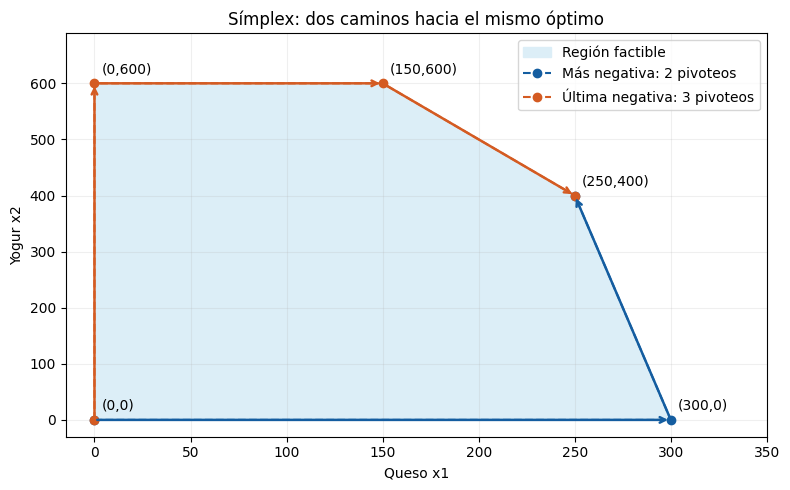

In [ ]:
vertices=np.array([[0,0],[300,0],[250,400],[150,600],[0,600]])
fig,ax=plt.subplots(figsize=(8,5))
ax.fill(vertices[:,0],vertices[:,1],color='#dceef7',label='Región factible')
for historia,color,label in [(hist,'#145da0','Más negativa: 2 pivoteos'),(hist_alt,'#d45b22','Última negativa: 3 pivoteos')]:
    puntos=np.array([[float(v['x1']),float(v['x2'])] for _,v in historia])
    ax.plot(puntos[:,0],puntos[:,1],'o--',color=color,label=label)
    for a,b in zip(puntos[:-1],puntos[1:]):
        ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',color=color,lw=1.8))
for a,b in vertices:
    ax.annotate(f'({a},{b})',(a,b),xytext=(5,7),textcoords='offset points')
ax.set(xlabel='Queso x1',ylabel='Yogur x2',title='Símplex: dos caminos hacia el mismo óptimo',xlim=(-15,350),ylim=(-30,690))
ax.legend(loc='upper right'); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

### **Actividad 2. Problema dual en PuLP**
Dual: $\min W=2400y_1+2700y_2+600y_3$; $8y_1+6y_2\ge9$; $y_1+3y_2+y_3\ge2.5$; $y\ge0$.

In [ ]:
import pulp

dual = pulp.LpProblem('dual_planta_quesera', pulp.LpMinimize)
y1 = pulp.LpVariable('y_leche', lowBound=0)
y2 = pulp.LpVariable('y_mano_obra', lowBound=0)
y3 = pulp.LpVariable('y_demanda', lowBound=0)

# TODO completos
dual += 2400*y1 + 2700*y2 + 600*y3, 'W'
dual += 8*y1 + 6*y2 >= 9, 'queso'
dual += y1 + 3*y2 + y3 >= 2.5, 'yogur'

dual.solve(pulp.PULP_CBC_CMD(msg=False))
print('Estado:', pulp.LpStatus[dual.status])
print('W* =', pulp.value(dual.objective))
print('y* =', y1.value(), y2.value(), y3.value())
for n,r in dual.constraints.items():
    print(n, 'precio dual =', r.pi)

Estado: Optimal
W* = 3250.000005
y* = 0.66666667 0.61111111 0.0
queso precio dual = 250.0
yogur precio dual = 400.0


#### Tabla 1. Verificación de la holgura complementaria

| Restricción primal | Holgura $s_i^*$ | Precio dual $y_i^*$ | Producto | ¿Se cumple? |
|---|---:|---:|---:|---|
| Leche | 0 | $2/3$ | 0 | Sí |
| Mano de obra | 0 | $11/18$ | 0 | Sí |
| Demanda de yogur | 200 | 0 | 0 | Sí |

También se cumple la condición para los productos: $250(8y_1+6y_2-9)=0$ y $400(y_1+3y_2+y_3-2,5)=0$.

#### **Pregunta 1. Compare Z (práctica 1) con W. ¿Qué teorema confirma?**
**Respuesta:** $Z^*=W^*=3250$. Confirma la **dualidad fuerte**: la máxima utilidad de producir coincide con la mínima valoración factible de los recursos. Las pequeñas diferencias decimales del solucionador son redondeo numérico.

#### **Pregunta 2.** Proponga una solución dual factible distinta de la óptima y calcule W. ¿Qué relación tiene con Z*? ¿Qué teorema ilustra?
**Respuesta:** con $y=(1,1,1)$ se cumple $8+6=14\ge9$ y $1+3+1=5\ge2,5$. Entonces $W=2400+2700+600=5700\ge3250$. Ilustra la **dualidad débil**: toda valoración dual factible es una cota superior de la utilidad primal.

#### **Pregunta 3. Explique, en términos del comprador de recursos, por qué $y_3^*=0$.**
**Respuesta:** solo se producen 400 de los 600 litros de yogur permitidos. El comprador no necesita pagar por ampliar un derecho de venta que la planta no utiliza completamente. Como ese límite tiene holgura de 200, su valoración marginal óptima es cero.

**Verificación numérica:** se comparan $Z^*$ y $W^*$ y se evalúa $W(1,1,1)$.

In [ ]:
Z_primal = 3250
W_dual = pulp.value(dual.objective)
print('Dualidad fuerte: Z* =', Z_primal, ' W* =', W_dual)
y_factible = (1,1,1)
W_factible = 2400*y_factible[0] + 2700*y_factible[1] + 600*y_factible[2]
print('Para y=(1,1,1), W =', W_factible, '>= Z* =', Z_primal)

Dualidad fuerte: Z* = 3250  W* = 3250.000005
Para y=(1,1,1), W = 5700 >= Z* = 3250


### **Actividad 3. Rangos de sensibilidad con HiGHS**
Se usa la función indicada en la guía para modelos $\max c^Tx$ s.a. $Ax\le b$, $x\ge0$.

In [ ]:
import numpy as np, highspy

def rangos(c, A, b, nombres_x, nombres_r, maximizar=True):
    h = highspy.Highs(); h.silent()
    inf = highspy.kHighsInf
    n = len(c)
    h.addVars(n, np.zeros(n), np.full(n, inf))
    signo = -1.0 if maximizar else 1.0
    h.changeColsCost(n, np.arange(n, dtype=np.int32), signo*np.array(c,float))
    for fila, lim in zip(A,b):
        h.addRow(-inf, lim, n, np.arange(n,dtype=np.int32), np.array(fila,float))
    h.setOptionValue("solver", "simplex")
    h.run()
    if h.getModelStatus() != highspy.HighsModelStatus.kOptimal:
        raise ValueError("El modelo no tiene solución óptima")
    sol = h.getSolution()
    res = h.getRanging(); rg = res[1] if isinstance(res, tuple) else res
    print(f'Z* = {signo*h.getInfo().objective_function_value:.2f}\n')
    print('Variable      valor  c. reducido    coef. mín   coef. máx')
    for j,nom in enumerate(nombres_x):
        lo,hi=sorted([signo*rg.col_cost_up.value_[j], signo*rg.col_cost_dn.value_[j]])
        print(f'{nom:18s} {sol.col_value[j]:8.2f} {signo*sol.col_dual[j]:12.2f} {lo:11.3f} {hi:11.3f}')
    print('\nRestricción uso      p. sombra    LD mín      LD máx')
    for i,nom in enumerate(nombres_r):
        ps=signo*sol.row_dual[i]
        if abs(ps)<1e-9 and b[i]-sol.row_value[i]>1e-7:
            lo,hi=f'{sol.row_value[i]:10.4f}',' sin límite'
        else:
            lo,hi=f'{rg.row_bound_dn.value_[i]:10.4f}', f'{rg.row_bound_up.value_[i]:10.4f}'
        print(f'{nom:18s} {sol.row_value[i]:8.2f} {ps:10.4f} {lo} {hi}')
    return h, sol, rg

rangos(c=[9,2.5], A=[[8,1],[6,3],[0,1]], b=[2400,2700,600],
       nombres_x=['queso','yogur'], nombres_r=['leche','mano_obra','demanda'])

Z* = 3250.00

Variable      valor  c. reducido    coef. mín   coef. máx
queso                250.00        -0.00       5.000      20.000
yogur                400.00        -0.00       1.125       4.500

Restricción uso      p. sombra    LD mín      LD máx
leche               2400.00     0.6667  1800.0000  3600.0000
mano_obra           2700.00     0.6111  1800.0000  3150.0000
demanda              400.00     0.0000   400.0000  sin límite


(<highspy.highs.Highs at 0x7a2ebfb64a70>,
 <highspy._core.HighsRanging at 0x7a2ebfbf72b0>)

#### Interpretación del reporte

| Dato que cambia por separado | Valor actual | Mínimo | Máximo |
|---|---:|---:|---:|
| Utilidad unitaria del queso | 9 | 5 | 20 |
| Utilidad unitaria del yogur | 2,50 | 1,125 | 4,50 |
| Leche disponible (L) | 2400 | 1800 | 3600 |
| Mano de obra (min) | 2700 | 1800 | 3150 |
| Límite de yogur (L) | 600 | 400 | Sin límite |

Los dos primeros intervalos mantienen óptima la producción de 250 y 400. Los demás mantienen válidos los respectivos precios sombra, aunque las cantidades producidas pueden cambiar. Se modifica **un dato a la vez**; en los extremos puede cambiar la base o haber óptimos alternativos.

#### Análisis paramétrico de la leche
Se resuelve $\max 9x_1+2,5x_2$, sujeto a $8x_1+x_2\le L$, $6x_1+3x_2\le2700$, $x_2\le600$, $x\ge0$, para distintos valores de $L$. La pendiente de $Z^*(L)$ mide el valor de un litro adicional.

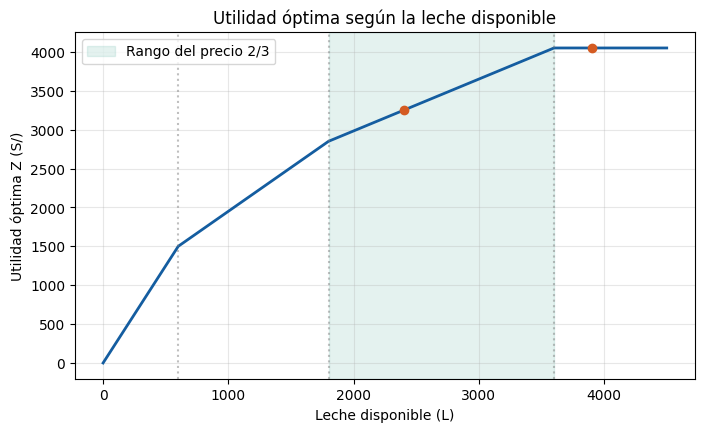

   0 a  600: pendiente promedio = 2.5000
 600 a 1800: pendiente promedio = 1.1250
1800 a 3600: pendiente promedio = 0.6667
3600 a 4500: pendiente promedio = 0.0000


In [ ]:
def utilidad_optima(leche):
    m = pulp.LpProblem('pq', pulp.LpMaximize)
    x1 = pulp.LpVariable('x1', lowBound=0)
    x2 = pulp.LpVariable('x2', lowBound=0)
    m += 9*x1 + 2.5*x2
    m += 8*x1 + x2 <= leche
    m += 6*x1 + 3*x2 <= 2700
    m += x2 <= 600
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    return pulp.value(m.objective)

niveles = np.arange(0,4501,100)
Z = np.array([utilidad_optima(L) for L in niveles])
plt.figure(figsize=(8,4.5))
plt.plot(niveles,Z,color='#145da0',lw=2)
plt.axvspan(1800,3600,color='#239a83',alpha=.12,label='Rango del precio 2/3')
for punto in [600,1800,3600]: plt.axvline(punto,color='gray',ls=':',alpha=.5)
plt.scatter([2400,3900],[3250,4050],color='#d45b22',zorder=5)
plt.title('Utilidad óptima según la leche disponible')
plt.legend()
plt.xlabel('Leche disponible (L)'); plt.ylabel('Utilidad óptima Z (S/)')
plt.grid(alpha=.3); plt.show()
pendientes = np.diff(Z)/np.diff(niveles)
for a,b in [(0,600),(600,1800),(1800,3600),(3600,4500)]:
    mask=(niveles[:-1]>=a)&(niveles[1:]<=b)
    print(f'{a:4d} a {b:4d}: pendiente promedio = {pendientes[mask].mean():.4f}')

#### Tabla 2. Precio sombra de la leche por tramos

| Leche (L) | Pendiente (S/ por L) | Restricción que explica el cambio |
|---|---:|---|
| 0 a 600 | 2,50 | Se dedica la leche a yogur; al llegar a 600 se agota su demanda. |
| 600 a 1800 | 1,125 = 9/8 | Yogur fijo en 600; la leche adicional se usa para queso. A 1800 se agota la mano de obra. |
| 1800 a 3600 | 2/3 ≈ 0,666667 | Leche y mano de obra activas; se sustituye yogur por queso. A 3600 el yogur llega a cero. |
| Más de 3600 | 0 | La mano de obra limita a 450 quesos; sobra leche. |

$$Z^*(L)=\begin{cases}2,5L&0\le L\le600\\1500+\frac98(L-600)&600\le L\le1800\\2850+\frac23(L-1800)&1800\le L\le3600\\4050&L\ge3600.\end{cases}$$

#### **Pregunta. La planta recibe 1500 L adicionales a S/ 0,50 por litro. Calcule la ganancia neta exacta. ¿Habría acertado usando solo el precio sombra 0,67?**
**Respuesta:** se pasa de 2400 a 3900 L. Solo los primeros 1200 L adicionales aportan utilidad: $1200(2/3)=800$. Los 300 L restantes aportan cero.

$$\text{Ganancia neta}=Z^*(3900)-Z^*(2400)-1500(0,50)=4050-3250-750=\boxed{S/\ 50}.$$

Usar 0,67 para toda la oferta daría S/ 255 y **sobrestimaría en S/ 205**. Incluso con el precio exacto $2/3$, aplicarlo a todos los litros daría S/ 250: el error principal es salir del rango, no el redondeo. Aceptar todo deja una ganancia positiva de S/ 50; si fuera posible comprar solo 1200 L al mismo precio, la ganancia sería S/ 200.

**Comprobación del cálculo:** se evalúan los dos óptimos y se descuenta el costo de compra.

In [ ]:
Z2400 = utilidad_optima(2400)
Z3900 = utilidad_optima(3900)
ganancia_bruta = Z3900-Z2400
costo_compra = 1500*0.50
print('Z(2400)=',Z2400,' Z(3900)=',Z3900)
print('Aumento utilidad=',ganancia_bruta)
print('Costo compra=',costo_compra)
print('Ganancia neta=',ganancia_bruta-costo_compra)
print('Estimación errónea usando 0.67 para todo:',1500*0.67-costo_compra)

Z(2400)= 3250.0  Z(3900)= 4050.0
Aumento utilidad= 800.0
Costo compra= 750.0
Ganancia neta= 50.0
Estimación errónea usando 0.67 para todo: 255.0000000000001


### **Actividad 4. Taller textil de fibra de alpaca — Parte A**
Variables continuas: $x_c$ chompas, $x_{ch}$ chalinas y $x_g$ gorros por semana.

$$\max Z=45x_c+18x_{ch}+8x_g$$
$$0,60x_c+0,25x_{ch}+0,15x_g\le60 \quad\text{(fibra)}$$
$$1,5x_c+0,5x_{ch}+0,4x_g\le160 \quad\text{(tejido)}$$
$$x_c+0,4x_{ch}+0,5x_g\le110 \quad\text{(acabado)}$$
$$x_c\le70,\qquad x_c,x_{ch},x_g\ge0.$$
Se usa la relajación continua solicitada; las cantidades fraccionarias no son un plan entero de fabricación.

In [ ]:
prod=['chompa','chalina','gorro']
util={'chompa':45,'chalina':18,'gorro':8}
uso={'fibra':{'chompa':0.60,'chalina':0.25,'gorro':0.15},
     'tejido':{'chompa':1.5,'chalina':0.5,'gorro':0.4},
     'acabado':{'chompa':1.0,'chalina':0.4,'gorro':0.5}}
disp={'fibra':60,'tejido':160,'acabado':110}

def taller(util,disp,dem_chompa=70,mostrar=True):
    m=pulp.LpProblem('taller_textil',pulp.LpMaximize)
    x=pulp.LpVariable.dicts('x',prod,lowBound=0)
    m += pulp.lpSum(util[p]*x[p] for p in prod)
    for r in disp:
        m += pulp.lpSum(uso[r][p]*x[p] for p in prod) <= disp[r], r
    m += x['chompa'] <= dem_chompa, 'demanda_chompa'
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    if mostrar:
        print('Z* =',round(pulp.value(m.objective),2))
        for p in prod: print(f'{p:8s}={x[p].value():7.2f}  costo reducido={x[p].dj:7.2f}')
        for n,c in m.constraints.items(): print(f'{n:15s} precio sombra={c.pi:8.3f} holgura={c.slack:8.2f}')
    return m,x

m_base,x_base=taller(util,disp)

Z* = 4446.0
chompa  =  70.00  costo reducido=   0.00
chalina =  72.00  costo reducido=   0.00
gorro   =   0.00  costo reducido=  -2.80
fibra           precio sombra=  72.000 holgura=   -0.00
tejido          precio sombra=  -0.000 holgura=   19.00
acabado         precio sombra=  -0.000 holgura=   11.20
demanda_chompa  precio sombra=   1.800 holgura=   -0.00


#### Reporte completo de sensibilidad del taller
Se usa el mismo modelo textil, con $c=(45,18,8)$ y disponibilidades $(60,160,110,70)$. Los intervalos se interpretan cambiando un dato a la vez. El costo reducido del gorro es −2,80: en S/ 10,80 puede haber alternativas óptimas; por encima conviene reoptimizar.

In [ ]:
_ = rangos([45,18,8], [[.6,.25,.15],[1.5,.5,.4],[1,.4,.5],[1,0,0]],
           [60,160,110,70], ['chompa','chalina','gorro'],
           ['fibra','tejido','acabado','demanda_chompa'])

Z* = 4446.00

Variable      valor  c. reducido    coef. mín   coef. máx
chompa                70.00        -0.00      43.200         inf
chalina               72.00        -0.00      13.333      18.750
gorro                  0.00        -2.80        -inf      10.800

Restricción uso      p. sombra    LD mín      LD máx
fibra                 60.00    72.0000    42.0000    67.0000
tejido               141.00     0.0000   141.0000  sin límite
acabado               98.80     0.0000    98.8000  sin límite
demanda_chompa        70.00     1.8000    -0.0000   100.0000


#### Cálculo de los cinco escenarios
Se mantiene el modelo textil y se cambia un dato por caso: utilidad del gorro a 11, fibra a 67 o 75, o demanda máxima de chompas a 100. Se comparan cantidades y utilidad óptima.

In [ ]:
escenarios=[]
def guardar(nombre,u,d,dem=70):
    m,x=taller(u,d,dem,False)
    escenarios.append([nombre]+[x[p].value() for p in prod]+[pulp.value(m.objective)])

guardar('a) Base',util,disp)
guardar('b) Gorro S/11',{**util,'gorro':11},disp)
guardar('c) Fibra 67 kg',util,{**disp,'fibra':67})
guardar('d) Fibra 75 kg',util,{**disp,'fibra':75})
guardar('e) Demanda chompas 100',util,disp,100)
for r in escenarios:
    print(f'{r[0]:24s} chompas={r[1]:7.2f} chalinas={r[2]:7.2f} gorros={r[3]:7.2f} Z={r[4]:8.2f}')

print('\nEscenario d - sensibilidad:')
taller(util,{**disp,'fibra':75})

a) Base                  chompas=  70.00 chalinas=  72.00 gorros=   0.00 Z= 4446.00
b) Gorro S/11            chompas=  70.00 chalinas=  46.15 gorros=  43.08 Z= 4454.62
c) Fibra 67 kg           chompas=  70.00 chalinas= 100.00 gorros=   0.00 Z= 4950.00
d) Fibra 75 kg           chompas=   0.00 chalinas= 275.00 gorros=   0.00 Z= 4950.00
e) Demanda chompas 100   chompas= 100.00 chalinas=   0.00 gorros=   0.00 Z= 4500.00

Escenario d - sensibilidad:
Z* = 4950.0
chompa  =   0.00  costo reducido=   0.00
chalina = 275.00  costo reducido=   0.00
gorro   =   0.00  costo reducido= -14.50
fibra           precio sombra=  -0.000 holgura=    6.25
tejido          precio sombra=  -0.000 holgura=   22.50
acabado         precio sombra=  45.000 holgura=   -0.00
demanda_chompa  precio sombra=  -0.000 holgura=   70.00


(taller_textil:
 MAXIMIZE
 18*x_chalina + 45*x_chompa + 8*x_gorro + 0.0
 SUBJECT TO
 fibra: 0.25 x_chalina + 0.6 x_chompa + 0.15 x_gorro <= 75
 
 tejido: 0.5 x_chalina + 1.5 x_chompa + 0.4 x_gorro <= 160
 
 acabado: 0.4 x_chalina + x_chompa + 0.5 x_gorro <= 110
 
 demanda_chompa: x_chompa <= 70
 
 VARIABLES
 x_chalina Continuous
 x_chompa Continuous
 x_gorro Continuous,
 {'chompa': x_chompa, 'chalina': x_chalina, 'gorro': x_gorro})

#### Tabla 3. Escenarios para la gerencia del taller

| Escenario | Chompas | Chalinas | Gorros | Z (S/) |
|---|---:|---:|---:|---:|
| a) Caso base | 70 | 72 | 0 | 4446,00 |
| b) Utilidad del gorro S/ 11 | 70 | 46,153846 | 43,076923 | 4454,615385 |
| c) Fibra 67 kg | 70 | 100 | 0 | 4950,00 |
| d) Fibra 75 kg — una solución óptima | 0 | 275 | 0 | 4950,00 |
| e) Hasta 100 chompas | 100 | 0 | 0 | 4500,00 |

**Óptimos alternativos en (d):** también son óptimas 70 chompas y 100 chalinas. En general, $x_g=0$, $x_{ch}=275-2,5x_c$, $0\le x_c\le70$ da Z=4950 y cumple las restricciones. Por ello distintos solucionadores pueden mostrar distintas cantidades con la misma utilidad.

#### **Pregunta 1. En (c), ¿coincide el aumento de Z con $7\times72$? ¿Y en (d) con $15\times72$? Explique la diferencia con el rango de la fibra.**
**Respuesta:** en (c), $4950-4446=504=7\times72$: sí coincide. Los 67 kg son el extremo superior del rango [42,67]. En (d), el aumento también es 504, no 1080; la predicción $4446+15\times72=5526$ es incorrecta. Después de 67 kg, más fibra por sí sola ya no aumenta la utilidad. Estos incrementos no descuentan un precio de compra adicional, que el enunciado no proporciona.

#### **Pregunta 2. En (d), ¿qué recurso pasa a ser el cuello de botella y cuál es su nuevo precio sombra?**
**Respuesta:** el **acabado**, con **S/ 45 por hora adicional**, dentro de su nuevo rango. La fibra pasa a tener precio sombra cero. Tanto una chompa como una chalina generan S/ 45 por hora de acabado ($45/1$ y $18/0,4$), lo que explica los óptimos alternativos.

#### **Pregunta 3. Redacte en cinco líneas una recomendación para la gerencia, sin términos técnicos.**
1. Con los recursos actuales, produzca 70 chompas y 72 chalinas por semana.
2. Conseguir 7 kg adicionales de fibra permite aumentar la utilidad semanal en S/ 504 antes del pago adicional.
3. No compre más fibra que esa cantidad sin ampliar también las horas disponibles para el acabado.
4. Considere fabricar gorros si su ganancia por unidad supera S/ 10,80 y revise el nuevo plan.
5. Negocie pedidos de hasta 100 chompas; con la fibra actual, ese cambio elevaría la utilidad a S/ 4500.

#### Gráfica de apoyo: utilidad por escenario
Se comparan los valores de $Z^*$ de la Tabla 3. Los casos (c) y (d) tienen la misma utilidad, aunque (d) dispone de más fibra.

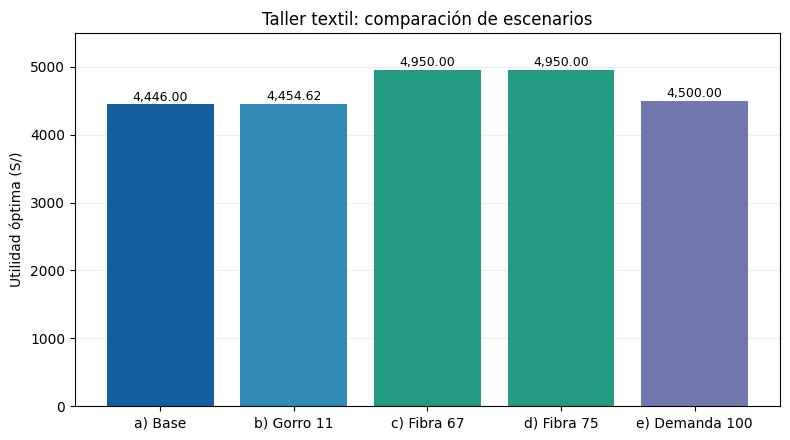

In [ ]:
fig,ax=plt.subplots(figsize=(8,4.5))
valores=[r[4] for r in escenarios]
ax.bar(['a) Base','b) Gorro 11','c) Fibra 67','d) Fibra 75','e) Demanda 100'],valores,color=['#145da0','#318bb5','#239a83','#239a83','#7078ae'])
for i,v in enumerate(valores): ax.text(i,v+55,f'{v:,.2f}',ha='center',fontsize=9)
ax.set(ylabel='Utilidad óptima (S/)',title='Taller textil: comparación de escenarios',ylim=(0,5500))
ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True); plt.tight_layout(); plt.show()

#### Parte B. LibreOffice Calc — modelo y comparación
Distribución completa para reproducir el caso base:

| Fila | A: concepto | B: chompa | C: chalina | D: gorro | E: resultado | F: disponibilidad |
|---|---|---:|---:|---:|---|---:|
| 2 | Cantidad óptima | 70 | 72 | 0 | — | — |
| 3 | Utilidad unitaria | 45 | 18 | 8 | `=SUMAPRODUCTO(B2:D2;B3:D3)` → 4446 | — |
| 5 | Fibra | 0,60 | 0,25 | 0,15 | `=SUMAPRODUCTO($B$2:$D$2;B5:D5)` → 60 | 60 |
| 6 | Tejido | 1,50 | 0,50 | 0,40 | `=SUMAPRODUCTO($B$2:$D$2;B6:D6)` → 141 | 160 |
| 7 | Acabado | 1,00 | 0,40 | 0,50 | `=SUMAPRODUCTO($B$2:$D$2;B7:D7)` → 98,8 | 110 |

**Configuración:** iniciar B2:D2 en cero; maximizar E3 cambiando B2:D2, con E5:E7 ≤ F5:F7, B2 ≤ 70 y variables no negativas. Elegir un motor lineal y mantener las variables continuas.

**Comparación con Python:** el resultado que debe reproducirse es (70,72,0), Z=4446. Las holguras se calculan como disponibilidad menos consumo: (0;19;11,2).

**¿Qué información de sensibilidad entrega Calc y cuál no?** En el flujo básico de Solver descrito por la guía se obtienen las cantidades y el objetivo; los usos y holguras se calculan en la hoja. Ese flujo no produce el reporte completo de precios sombra, costos reducidos e intervalos utilizado aquí con HiGHS. Las funciones adicionales dependen del motor y de la versión instalada.

**¿Por qué se prefiere Python? (dos líneas)**  
Python permite repetir los escenarios automáticamente y mantener juntos el modelo, los cálculos y las gráficas.  
PuLP y HiGHS permiten consultar precios sombra, costos reducidos y rangos para explicar las decisiones.